## Exploratory Data Analysis

### Roles to Explore: 

In [2]:
import ast 
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading the data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()


# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

### Filter for US Data Analyst Roles

In [3]:
df_DA_US = df[(df['job_country'] == 'United States') & (df['job_title_short'] == 'Data Analyst')].copy()

C:\Users\Soumyajit\AppData\Local\Temp\ipykernel_36456\1921364519.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = df_plot, x = 'count', y = 'job_location', palette = 'dark:b', legend = False)


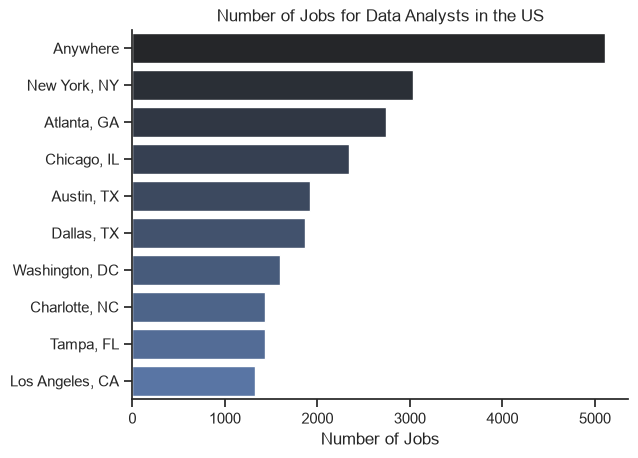

In [10]:
df_plot = df_DA_US['job_location'].value_counts().head(10).to_frame()

sns.set_theme(style = 'ticks')
sns.barplot(data = df_plot, x = 'count', y = 'job_location', palette = 'dark:b', legend = False)
sns.despine()
plt.title('Number of Jobs for Data Analysts in the US')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

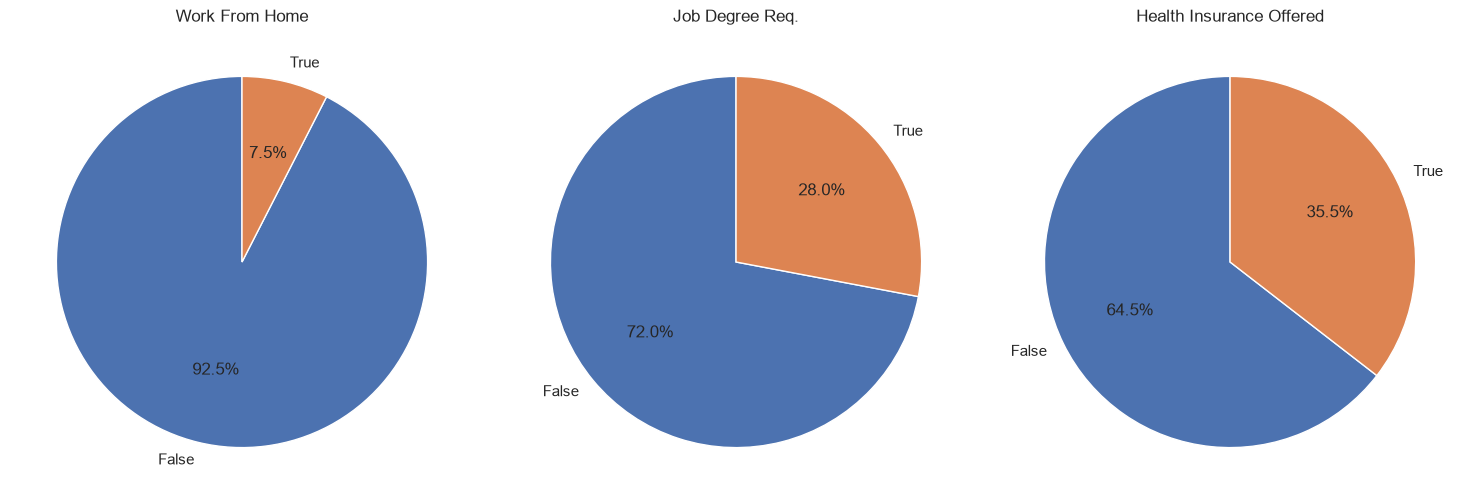

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

dict_column = {
    'job_work_from_home': 'Work From Home',
    'job_no_degree_mention': 'Job Degree Req.',
    'job_health_insurance': 'Health Insurance Offered'
}

for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(
        df_DA_US[column].value_counts(),
        labels=df_DA_US[column].value_counts().index,
        autopct='%1.1f%%', startangle = 90
    )
    ax[i].set_title(title)

plt.tight_layout()
plt.show()

C:\Users\Soumyajit\AppData\Local\Temp\ipykernel_36456\3936706696.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = df_plot, x = 'count', y = 'company_name', palette = 'dark:b', legend = False)


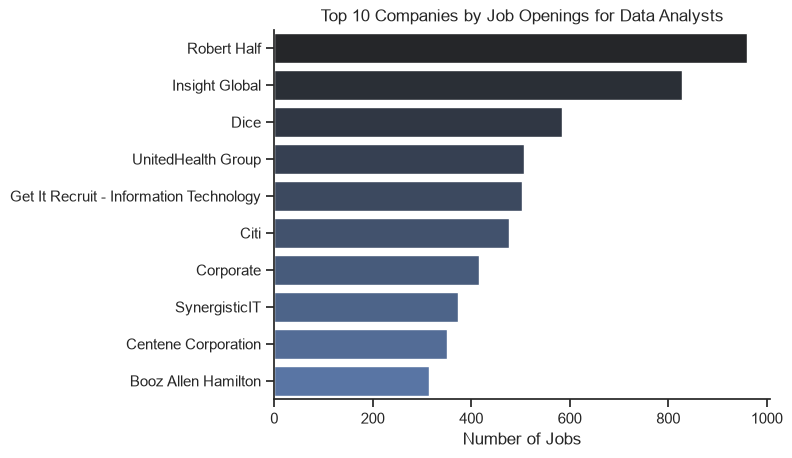

In [13]:
df_plot = df_DA_US['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style = 'ticks')
sns.barplot(data = df_plot, x = 'count', y = 'company_name', palette = 'dark:b', legend = False)
sns.despine()
plt.title('Top 10 Companies by Job Openings for Data Analysts')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()